# 02 · Rocchio and kNN

Maths units **M1** (cosine) and **M2** (Rocchio). Read `rec/r1_rocchio.py` and `rec/r2_knn.py` first.

R1 averages the likes into one direction and scores by cosine to it. R2 keeps every like and scores by similarity to the nearest few. This notebook checks M2 by hand, shows both on a simulated profile, and measures the cost difference that made R2 a reference rung rather than a serving one (DECISIONS #14).

**Everything below that involves a user is SIMULATED** (`eval/sim.py`). Real labels only exist once Alen swipes.

In [1]:
import glob, json, time
import numpy as np
import matplotlib.pyplot as plt

from visualtaste.api.deps import AppState
from visualtaste.config import get_settings

state = AppState(get_settings())
state.load()
features = state.require_features()
print(f"{len(features):,} pool images loaded")

Archive ladder reached rule 5: no external drive and only 42.7 GB free. Using the internal fallback by prior decision (docs/DECISIONS.md #2).


50,000 pool images loaded


## 1 · M2 by hand

In [2]:
from visualtaste.rec.r1_rocchio import rocchio_vector

u = rocchio_vector(np.array([[1.0, 0.0], [0.8, 0.6]]), np.array([[0.0, 1.0]]))
print("u_hat =", np.round(u, 3))
for x in ([0.6, 0.8], [1, 0], [0, 1]):
    print(x, "->", round(float(np.array(x) @ u), 3))

u_hat = [ 0.976 -0.217]
[0.6, 0.8] -> 0.412
[1, 0] -> 0.976
[0, 1] -> -0.217


## 2 · Both rungs on a simulated profile

A simulated S1 user rates 300 random pool images. R1 and R2 are fitted on them and score the rest. A good scorer separates what the user would like from what they would not; the simulator knows that truth.

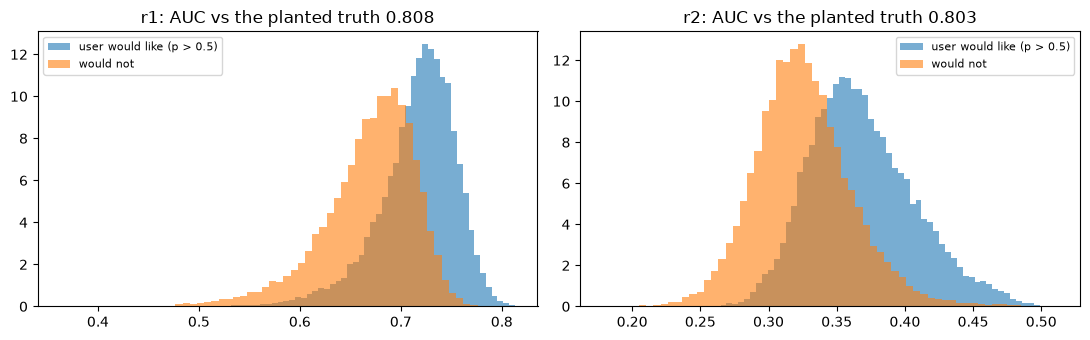

In [3]:
from visualtaste.eval.sim import make_variant_user
from visualtaste.rec.labels import ACTION_TO_TARGET, DEFAULT_ACTION_WEIGHTS, LabelSet
from visualtaste.rec.r1_rocchio import RocchioRecommender
from visualtaste.rec.r2_knn import KnnRecommender
from visualtaste.eval.metrics import roc_auc

rng = np.random.default_rng(1729)
user = make_variant_user("S1_semantic", features, seed=1729, cluster_labels=features.cluster64)
shown = rng.choice(len(features), 300, replace=False)
actions = user.react_rows(features, shown)
labels = LabelSet(
    image_ids=[features.image_ids[i] for i in shown],
    targets=np.array([ACTION_TO_TARGET[a] for a in actions], dtype=np.float32),
    weights=np.array([DEFAULT_ACTION_WEIGHTS[a] for a in actions], dtype=np.float32),
    actions=actions, timestamps=[""] * len(shown),
)
rest = np.setdiff1d(np.arange(len(features)), shown)
truth = user.like_probability(features.siglip[rest])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, model in zip(axes, (RocchioRecommender(), KnnRecommender(neighbours=5))):
    model.fit(labels, features)
    score = model.score(features, rest)
    likely = truth > 0.5
    ax.hist(score[likely], bins=60, alpha=0.6, density=True, label="user would like (p > 0.5)")
    ax.hist(score[~likely], bins=60, alpha=0.6, density=True, label="would not")
    ax.set_title(f"{model.rung}: AUC vs the planted truth {roc_auc(likely.astype(int), score):.3f}")
    ax.legend(fontsize=8)
plt.tight_layout()

## 3 · Why R2 is not served: cost grows with the labels (F2, F3)

R1 scores with one 50,000-row matrix-vector product whatever the label count. R2 compares every candidate with every like.

In [4]:
from visualtaste.rec.labels import LabelSet

def timed(model, n_labels, repeats=5):
    idx = rng.choice(len(features), n_labels, replace=False)
    acts = user.react_rows(features, idx)
    lab = LabelSet([features.image_ids[i] for i in idx],
                   np.array([ACTION_TO_TARGET[a] for a in acts], np.float32),
                   np.array([DEFAULT_ACTION_WEIGHTS[a] for a in acts], np.float32), acts, [""] * n_labels)
    model.fit(lab, features)
    candidates = np.arange(len(features))
    t = []
    for _ in range(repeats):
        start = time.perf_counter(); model.score(features, candidates); t.append(time.perf_counter() - start)
    return 1000 * np.median(t)

for n in (100, 300, 1000):
    print(f"{n:>5} labels   R1 {timed(RocchioRecommender(), n):6.1f} ms   R2 {timed(KnnRecommender(), n):7.1f} ms")

  100 labels   R1    7.8 ms   R2   144.3 ms


  300 labels   R1    9.6 ms   R2   230.1 ms


 1000 labels   R1    8.2 ms   R2   502.1 ms


The measured numbers above, not the ones in this sentence, are the result; the shape is the point: R1 stays flat and R2 grows with the label count. At 1,000 labels R2 alone uses more than the feed's 50 ms budget, which is why it stays a teaching rung (DECISIONS #14). The gather-versus-product lesson (F2, DECISIONS #13) is in `rec/r1_rocchio.score`'s docstring.